## Assignment 3
Name: Prachi Kumari

Streamlit Link: https://ind320project-6dme9afld5jprddxdm8ds6.streamlit.app/

GitHub repo Link: https://github.com/prakum04/IND320_Project/blob/main/

##### Importing libraries

In [1]:
# Importing important libraries
import pandas as pd
import random as rd
import geopandas as gpd


##### Reading the shapefiles

In [2]:
areas = gpd.read_file(
    r"C:\Projects\IND320_Project\data\Budomr├Ñder\Budomr├Ñder.shp"
)
areas.head()

,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


##### Selecting NO1 - NO5 regions

In [3]:
#Choosing the first NO1 column

no1 = areas[areas["budomr"] == "NO 1"]
no1
no2 = areas[areas["budomr"] == "NO 2"]
no3 = areas[areas["budomr"] == "NO 3"]
no4 = areas[areas["budomr"] == "NO 4"]
no5 = areas[areas["budomr"] == "NO 5"]

##### Sampling method
Generating random points within each region bouding rectangle and choose to keep those inside its polygon. Until it has 1000 points per region. 

In [4]:
from shapely.geometry import Point
import random as rd

# Make the random samples reproducible.
rd.seed(42)

# All generated points use the same CRS as areas (EPSG:25833).
print(areas.crs)

# ----- NO1 -----
polygon = no1["geometry"].iloc[0]
bounds = polygon.bounds
points_list = []

# Generate candidates until 1,000 points are inside the region.
while len(points_list) < 1000:
    x = rd.uniform(bounds[0], bounds[2])
    y = rd.uniform(bounds[1], bounds[3])
    point = Point(x, y)

    if polygon.contains(point):
        points_list.append(point)

points_no1 = points_list

# ----- NO2 -----
polygon = no2["geometry"].iloc[0]
bounds = polygon.bounds
points_list = []

while len(points_list) < 1000:
    x = rd.uniform(bounds[0], bounds[2])
    y = rd.uniform(bounds[1], bounds[3])
    point = Point(x, y)

    if polygon.contains(point):
        points_list.append(point)

points_no2 = points_list

# ----- NO3 -----
polygon = no3["geometry"].iloc[0]
bounds = polygon.bounds
points_list = []

while len(points_list) < 1000:
    x = rd.uniform(bounds[0], bounds[2])
    y = rd.uniform(bounds[1], bounds[3])
    point = Point(x, y)

    if polygon.contains(point):
        points_list.append(point)

points_no3 = points_list

# ----- NO4 -----
polygon = no4["geometry"].iloc[0]
bounds = polygon.bounds
points_list = []

while len(points_list) < 1000:
    x = rd.uniform(bounds[0], bounds[2])
    y = rd.uniform(bounds[1], bounds[3])
    point = Point(x, y)

    if polygon.contains(point):
        points_list.append(point)

points_no4 = points_list

# ----- NO5 -----
polygon = no5["geometry"].iloc[0]
bounds = polygon.bounds
points_list = []

while len(points_list) < 1000:
    x = rd.uniform(bounds[0], bounds[2])
    y = rd.uniform(bounds[1], bounds[3])
    point = Point(x, y)

    if polygon.contains(point):
        points_list.append(point)

points_no5 = points_list

# Check that each region has 1,000 accepted points.
print("NO1:", len(points_no1))
print("NO2:", len(points_no2))
print("NO3:", len(points_no3))
print("NO4:", len(points_no4))
print("NO5:", len(points_no5))

EPSG:25833
NO1: 1000
NO2: 1000
NO3: 1000
NO4: 1000
NO5: 1000


##### Coordinate conversion
Converted coordinates so that it can supply longitude and latitude to Open- Meteo. 

In [5]:
# Assign the original CRS, then convert from metres to longitude/latitude.
points_no1_geo = gpd.GeoDataFrame(geometry=points_no1, crs=areas.crs).to_crs(epsg=4326)
points_no2_geo = gpd.GeoDataFrame(geometry=points_no2, crs=areas.crs).to_crs(epsg=4326)
points_no3_geo = gpd.GeoDataFrame(geometry=points_no3, crs=areas.crs).to_crs(epsg=4326)
points_no4_geo = gpd.GeoDataFrame(geometry=points_no4, crs=areas.crs).to_crs(epsg=4326)
points_no5_geo = gpd.GeoDataFrame(geometry=points_no5, crs=areas.crs).to_crs(epsg=4326)

# Check the converted coordinate system and first few points.
print(points_no1_geo.crs)
print(points_no1_geo.head())

EPSG:4326
                    geometry
0   POINT (9.62161 59.62546)
1  POINT (11.56532 61.51978)
2   POINT (11.2057 60.97879)
3   POINT (9.11049 61.08239)
4  POINT (11.89659 61.61416)


In [6]:
# Each pair is ordered as (longitude, latitude).
coordinates_by_region = {
    "NO 1": list(zip(points_no1_geo.geometry.x, points_no1_geo.geometry.y)),
    "NO 2": list(zip(points_no2_geo.geometry.x, points_no2_geo.geometry.y)),
    "NO 3": list(zip(points_no3_geo.geometry.x, points_no3_geo.geometry.y)),
    "NO 4": list(zip(points_no4_geo.geometry.x, points_no4_geo.geometry.y)),
    "NO 5": list(zip(points_no5_geo.geometry.x, points_no5_geo.geometry.y)),
}

# Display the first three coordinate pairs for NO1.
print(coordinates_by_region["NO 1"][:3])

[(9.621610633873773, 59.62545564601554), (11.565316920438045, 61.51977804699225), (11.205702558742171, 60.978785139542936)]


In [7]:
import random

import geopandas as gpd
from shapely.geometry import Point



precipitation_areas = gpd.read_file(
    r"C:\Projects\IND320_Project\data\NVE_Region\NVE_Region.shp",
    encoding="utf-8",
)

# Clean the region codes and check that the expected regions are present.
precipitation_areas["REGION"] = (
    precipitation_areas["REGION"].str.strip().str.upper()
)

region_groups = {
    "RS": "East",
    "R├ÿ": "East",
    "RM": "North",
    "RN": "North",
    "RV": "West",
}

found_codes = set(precipitation_areas["REGION"].dropna())
missing_codes = set(region_groups) - found_codes
if missing_codes:
    raise ValueError(f"Missing region codes: {sorted(missing_codes)}")

# Combine polygons belonging to the same precipitation region.
precipitation_areas["group"] = precipitation_areas["REGION"].map(region_groups)
precipitation_regions = precipitation_areas.to_crs(areas.crs).dissolve(by="group")

# Sample 1,000 points inside each combined polygon.
rng = random.Random(42)
precipitation_coordinates = {}

for region, polygon in precipitation_regions.geometry.items():
    min_x, min_y, max_x, max_y = polygon.bounds
    points = []

    while len(points) < 1000:
        point = Point(
            rng.uniform(min_x, max_x),
            rng.uniform(min_y, max_y),
        )
        if polygon.contains(point):
            points.append(point)

    # Store the sampled points as (longitude, latitude) pairs.
    points_geo = gpd.GeoSeries(points, crs=precipitation_regions.crs)
    points_geo = points_geo.to_crs(epsg=4326)
    precipitation_coordinates[region] = list(zip(points_geo.x, points_geo.y))

    print(f"{region}: {len(points)} points")

East: 1000 points
North: 1000 points
West: 1000 points


In [8]:
import json
from pathlib import Path

output = Path(r"C:\Projects\IND320_Project\data\weather_coordinates.json")

coordinates = {
    **coordinates_by_region,       # NO 1 through NO 5
    **precipitation_coordinates,   # East, North, West
}

output.write_text(json.dumps(coordinates), encoding="utf-8")
print({region: len(points) for region, points in coordinates.items()})

{'NO 1': 1000, 'NO 2': 1000, 'NO 3': 1000, 'NO 4': 1000, 'NO 5': 1000, 'East': 1000, 'North': 1000, 'West': 1000}


In [9]:
import requests
import pandas as pd
from pathlib import Path
import time

def download_weather(region_id, start_date, end_date, max_locations=2):
    # Look up the sampled longitudeÔÇôlatitude pairs.
    coordinates = coordinates_by_region[region_id]

    if max_locations is not None:
        coordinates = coordinates[:max_locations]

    url = "https://archive-api.open-meteo.com/v1/archive"
    tables = []

    # Create a folder for this region and time interval.
    folder = Path("weather_downloads") / f"{region_id}_{start_date}_{end_date}"
    folder.mkdir(parents=True, exist_ok=True)

    for location_id, (longitude, latitude) in enumerate(coordinates):
        file_path = folder / f"location_{location_id}.csv"

        # Load an existing file and skip downloading this location.
        if file_path.exists():
            weather_df = pd.read_csv(file_path)
            weather_df["time"] = pd.to_datetime(weather_df["time"], utc=True)
            tables.append(weather_df)
            print(f"Loaded saved location {location_id + 1}")
            continue

        # Request hourly ERA5 temperature and precipitation.
        params = {
            "longitude": longitude,
            "latitude": latitude,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "models": "era5",
            "timezone": "UTC"
        }

                # Try at most five times if the API rate limit is reached.
        for attempt in range(5):
            response = requests.get(url, params=params, timeout=120)

            # Other responses leave the retry loop.
            if response.status_code != 429:
                break

            # On the last attempt, raise the error instead of waiting again.
            if attempt == 4:
                response.raise_for_status()

            # Increase the wait after each rate-limit response.
            wait_seconds = 60 * (2 ** attempt)
            print(f"Rate limit reached. Waiting {wait_seconds} seconds.")
            time.sleep(wait_seconds)

        # Report HTTP errors and decode successful responses.
        response.raise_for_status()
        data = response.json()

        # Convert the response to a table.
        weather_df = pd.DataFrame(data["hourly"])
        weather_df["time"] = pd.to_datetime(weather_df["time"], utc=True)

        # Identify the region and requested location.
        weather_df["region"] = region_id
        weather_df["location_id"] = location_id
        weather_df["longitude"] = longitude
        weather_df["latitude"] = latitude

        # Save each completed download before moving to the next location.
        weather_df.to_csv(file_path, index=False)
        tables.append(weather_df)
        print(f"Downloaded location {location_id + 1}/{len(coordinates)}")

    return pd.concat(tables, ignore_index=True)

In [10]:
weather_no3 = download_weather(
    "NO 3", "2024-01-01", "2024-12-31",
    max_locations=None
)

print(weather_no3.shape)
print(weather_no3["location_id"].nunique())

Loaded saved location 1
Loaded saved location 2
Loaded saved location 3
Loaded saved location 4
Loaded saved location 5
Loaded saved location 6
Loaded saved location 7
Loaded saved location 8
Loaded saved location 9
Loaded saved location 10
Loaded saved location 11
Loaded saved location 12
Loaded saved location 13
Loaded saved location 14
Loaded saved location 15
Loaded saved location 16
Loaded saved location 17
Loaded saved location 18
Loaded saved location 19
Loaded saved location 20
Loaded saved location 21
Loaded saved location 22
Loaded saved location 23
Loaded saved location 24
Loaded saved location 25
Loaded saved location 26
Loaded saved location 27
Loaded saved location 28
Loaded saved location 29
Loaded saved location 30
Loaded saved location 31
Loaded saved location 32
Loaded saved location 33
Loaded saved location 34
Loaded saved location 35
Loaded saved location 36
Loaded saved location 37
Loaded saved location 38
Loaded saved location 39
Loaded saved location 40
Loaded sa

In [11]:
# Check that every location has a complete leap year.
counts = weather_no3.groupby("location_id").size()
print("All locations have 8784 hours:", counts.eq(8784).all())

# Check missing weather values and duplicate records.
print(weather_no3[["temperature_2m", "precipitation"]].isna().sum())
print("Duplicates:", weather_no3.duplicated(["location_id", "time"]).sum())

All locations have 8784 hours: True
temperature_2m    0
precipitation     0
dtype: int64
Duplicates: 0


In [12]:
# Calculate regional averages separately for every hour.
weather_hourly = (
    weather_no3
    .groupby("time")[["temperature_2m", "precipitation"]]
    .mean()
    .sort_index()
)

print(weather_hourly.shape)  # Expected: (8784, 2)
weather_hourly.head()

(8784, 2)


,temperature_2m,precipitation
time,,
2024-01-01 00:00:00+00:00,-3.7048,0.0028
2024-01-01 01:00:00+00:00,-3.8436,0.0020
2024-01-01 02:00:00+00:00,-3.8159,0.0019
2024-01-01 03:00:00+00:00,-3.8443,0.0019
2024-01-01 04:00:00+00:00,-3.7824,0.0018


In [13]:
from pathlib import Path

output = Path(r"C:\Projects\IND320_Project\data\no3_weather_hourly_2024.csv")
output.parent.mkdir(parents=True, exist_ok=True)

weather_hourly.rename_axis("time").to_csv(output)
print(f"Saved {len(weather_hourly):,} rows to {output}")

Saved 8,784 rows to C:\Projects\IND320_Project\data\no3_weather_hourly_2024.csv


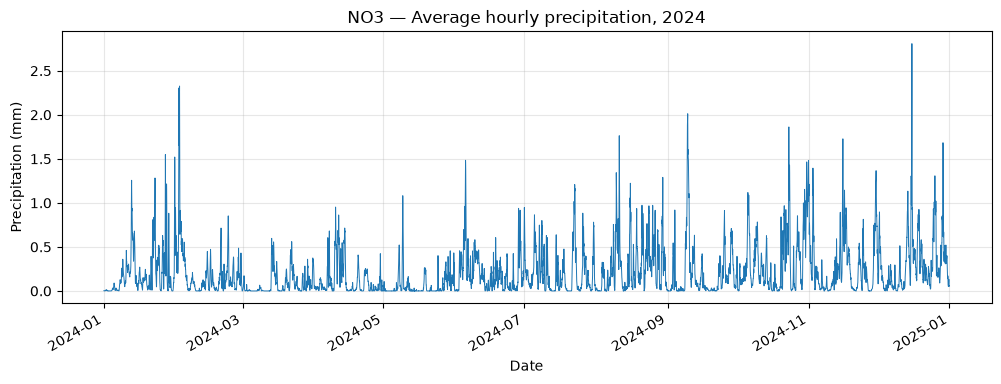

In [ ]:
import matplotlib.pyplot as plt

# Ploting hourly average precipitation across NO3.
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    weather_hourly.index,
    weather_hourly["precipitation"],
    linewidth=0.7
)

ax.set(
    title="NO3 ÔÇö Average hourly precipitation, 2024",
    xlabel="Date",
    ylabel="Precipitation (mm)"
)

ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

##### Graph comment
The X-axis shows the date and the line containse one value per hour. The Y-axis shows the average preciptiation during that hour, in milimeters. The highes spike seems to be at about 2.8 mm in one hour in December. Values near zero mean little or no precipitation across the sampled locations. 

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.fft import dct, idct


def plot_precipitation_spc(weather_hourly, cutoff=30, n_std=3):
    """Return the precipitation SPC plot, flagged hours, and summary."""
    series = weather_hourly["precipitation"].sort_index()
    values = series.to_numpy(dtype=float)

    if not 1 <= cutoff < len(values):
        raise ValueError("cutoff must be between 1 and the series length minus 1.")
    if n_std <= 0:
        raise ValueError("n_std must be positive.")

    # Remove the lowest-frequency DCT coefficients.
    coefficients = dct(values, type=1, norm="forward")
    coefficients[:cutoff] = 0
    variations = idct(coefficients, type=1, norm="forward")
    smooth_component = values - variations

    # Estimate the centre and spread from the whole year.
    centre = stats.trim_mean(variations, proportiontocut=0.05)
    robust_sd = stats.median_abs_deviation(variations) * 1.4826
    half_width = n_std * robust_sd

    # Flag outliers and shift the limits onto the original precipitation scale.
    outlier_mask = np.abs(variations - centre) > half_width
    lower = smooth_component + centre - half_width
    upper = smooth_component + centre + half_width
    outliers = series.loc[outlier_mask].to_frame()

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, values, linewidth=0.7, label="Average precipitation")
    ax.plot(series.index, lower, "--", color="orange", label="Lower SPC limit")
    ax.plot(series.index, upper, "--", color="green", label="Upper SPC limit")
    ax.scatter(
        outliers.index, outliers["precipitation"],
        color="red", s=12, zorder=3, label="Outliers"
    )
    ax.set(
        title="Average hourly precipitation with robust SPC limits",
        xlabel="Date",
        ylabel="Precipitation (mm)"
    )
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()

    summary = {
        "Outlier hours": len(outliers),
        "Outlier percentage": round(100 * outlier_mask.mean(), 2),
        "Robust standard deviation": robust_sd,
    }
    return fig, outliers, summary

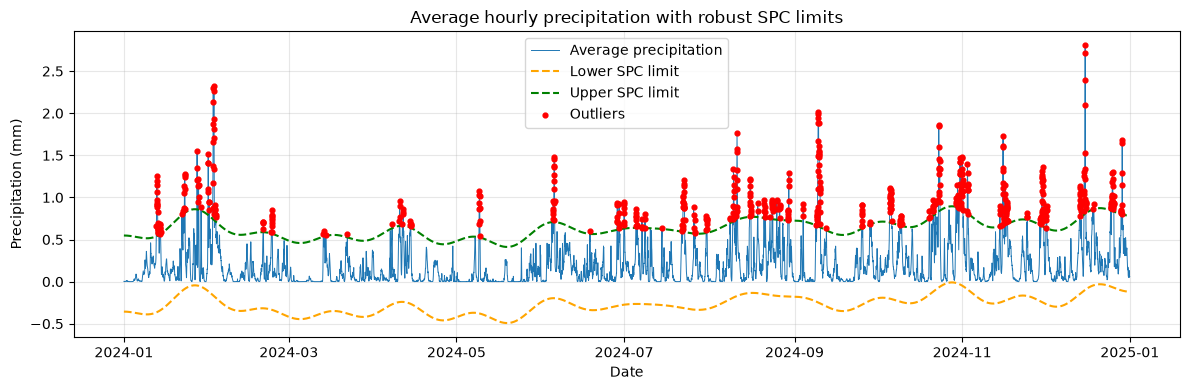

{'Outlier hours': 561,
 'Outlier percentage': np.float64(6.39),
 'Robust standard deviation': np.float64(0.15065101757779104)}

,precipitation
time,
2024-01-12 20:00:00+00:00,0.6600
2024-01-12 21:00:00+00:00,0.8910
2024-01-12 22:00:00+00:00,1.0591
2024-01-12 23:00:00+00:00,1.2000
2024-01-13 00:00:00+00:00,1.2564


In [16]:
fig_spc, spc_outliers, spc_summary = plot_precipitation_spc(
    weather_hourly, cutoff=30, n_std=3
)

display(fig_spc)
plt.close(fig_spc)
display(spc_summary)
display(spc_outliers.head())

#### Graph comment
The blue line shows the hourly precipitation, which is averaged over 1000 sampled locations. 
Orange and green dashed line controlls the upper and lower control limits. They flacutes over time as the baseline changes. The red dots illustrates the hours outside the control limits. In this case the falgged hours are above the upper limit, so they represent unusally we hours under the chosen settings. 561 hours of 8784 hours was flagged. 

In [17]:
from sklearn.neighbors import LocalOutlierFactor

def plot_temperature_lof(weather_hourly, outlier_fraction=0.01, n_neighbors=20):
    """Plot average temperature and highlight LOF anomalies."""
    series = weather_hourly["temperature_2m"].sort_index()
    values = series.to_numpy(dtype=float)

    # Validate the data and adjustable parameters.
    if len(values) < 3 or not np.isfinite(values).all():
        raise ValueError("Provide at least three finite temperature values.")

    if not 0 < outlier_fraction <= 0.5:
        raise ValueError("outlier_fraction must be between 0 and 0.5.")

    if not isinstance(n_neighbors, (int, np.integer)) or n_neighbors < 2:
        raise ValueError("n_neighbors must be an integer of at least 2.")

    # Scikit-learn expects rows of observations and columns of features.
    X = values.reshape(-1, 1)

    model = LocalOutlierFactor(
        n_neighbors=min(n_neighbors, len(values) - 1),
        contamination=outlier_fraction
    )

    # LOF returns -1 for anomalies and 1 for ordinary observations.
    labels = model.fit_predict(X)
    anomaly_mask = labels == -1

    results = pd.DataFrame({
        "temperature_2m": values,
        # Reverse the sign so larger scores indicate stronger anomalies.
        "lof_score": -model.negative_outlier_factor_,
        "is_anomaly": anomaly_mask
    }, index=series.index)

    anomalies = results.loc[anomaly_mask].copy()

    summary = {
        "observations": len(values),
        "anomaly_hours": int(anomaly_mask.sum()),
        "anomaly_percentage": float(anomaly_mask.mean() * 100),
        "requested_outlier_fraction": outlier_fraction,
        "n_neighbors": model.n_neighbors_
    }

    # Show anomalies on the original temperature time series.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(
        series.index, values,
        linewidth=0.7, label="Average temperature"
    )
    ax.scatter(
        anomalies.index, anomalies["temperature_2m"],
        color="red", s=18, label="LOF anomalies", zorder=3
    )

    ax.set(
        title="Temperature ÔÇö Local Outlier Factor",
        xlabel="Date",
        ylabel="Temperature (┬░C)"
    )
    ax.legend()
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    return fig, anomalies, summary

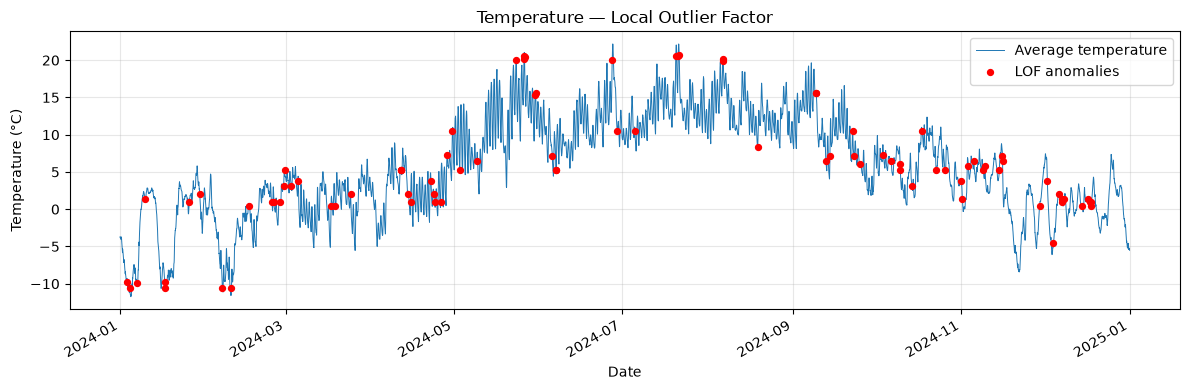

observations                  8784.000000
anomaly_hours                   88.000000
anomaly_percentage               1.001821
requested_outlier_fraction       0.010000
n_neighbors                     20.000000
Name: Value, dtype: float64

,temperature_2m,lof_score,is_anomaly
time,,,
2024-11-08 22:00:00+00:00,5.2350,1.556195,True
2024-04-11 19:00:00+00:00,5.2352,1.551465,True
2024-10-09 21:00:00+00:00,5.2355,1.545159,True
2024-02-29 15:00:00+00:00,5.2332,1.537689,True
2024-05-03 03:00:00+00:00,5.2334,1.532885,True


In [18]:
fig_lof, lof_anomalies, lof_summary = plot_temperature_lof(
    weather_hourly,
    outlier_fraction=0.01
)

display(fig_lof)
plt.close(fig_lof)
display(pd.Series(lof_summary, name="Value"))

# Display the strongest anomalies first.
display(lof_anomalies.sort_values("lof_score", ascending=False).head())

#### Graph comment
The blue line is the temprature in celcisus avreged acrros the 1000 sampled locations for each hour. The red dods are the hours flagged by (LOF). The method looks at the 20 readings closest in tempreature and checks how densly they are grouped. Which is why the red dots can come at moderate tempreatures as well as at the hottest and coldest points. W

##### Reservoir data: STL and spectrogram

In [ ]:
import requests
import pandas as pd

# Downloading reservoir statistics from NVE.
nve_url = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)

response = requests.get(nve_url, timeout=60)
response.raise_for_status()

reservoir_data = pd.DataFrame(response.json())

# Giving the columns descriptive names.
reservoir_data = reservoir_data.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "fyllingsgrad": "fill_level"
})

reservoir_data["date"] = pd.to_datetime(reservoir_data["date"])
reservoir_data = reservoir_data.sort_values("date")

# Inspecting the available area types and numbers before selecting a series.
display(
    reservoir_data[["area_type", "area_number"]]
    .drop_duplicates()
    .sort_values(["area_type", "area_number"])
)

,area_type,area_number
7718,EL,1
7118,EL,2
4415,EL,3
8286,EL,4
2980,EL,5
9941,NO,0
14350,VASS,1
11256,VASS,2
14892,VASS,3


In [ ]:
# Selecting electricity area NO3.
reservoir_no3 = reservoir_data.loc[
    (reservoir_data["area_type"] == "EL")
    & (reservoir_data["area_number"] == 3),
    ["date", "fill_level"]
].copy()

# Converting filling fractions to percentages and sorting chronologically.
reservoir_no3["fill_level"] = (
    pd.to_numeric(reservoir_no3["fill_level"], errors="coerce") * 100
)
reservoir_no3 = reservoir_no3.sort_values("date")

# Checking the series before applying STL.
print("Observations:", len(reservoir_no3))
print("First date:", reservoir_no3["date"].min())
print("Last date:", reservoir_no3["date"].max())
print("Missing values:", reservoir_no3["fill_level"].isna().sum())
print("Duplicate dates:", reservoir_no3["date"].duplicated().sum())

# Most consecutive observations should be seven days apart.
print("\nTime between observations:")
print(reservoir_no3["date"].diff().value_counts())

reservoir_no3.head()

Observations: 1661
First date: 1995-01-08 00:00:00
Last date: 2026-11-01 00:00:00
Missing values: 0
Duplicate dates: 0

Time between observations:
date
7 days    1660
Name: count, dtype: int64


,date,fill_level
4415,1995-01-08,60.237580
4282,1995-01-15,56.994265
3985,1995-01-22,54.220300
4013,1995-01-29,50.814770
4713,1995-02-05,47.388270


In [21]:

from statsmodels.tsa.seasonal import STL

def plot_reservoir_stl(
    reservoir_df,
    seasonal_smoother=19,
    trend_smoother=83,
    robust=True
):
    """Decompose weekly filling levels into trend, seasonality and residuals."""

    # Create a weekly time series from the already checked data.
    series = (
        reservoir_df
        .sort_values("date")
        .set_index("date")["fill_level"]
        .asfreq("W-SUN")
    )

    if series.isna().any():
        raise ValueError("The weekly series contains missing values.")

    # STL requires odd smoother lengths and a trend window above the period.
    if seasonal_smoother < 3 or seasonal_smoother % 2 == 0:
        raise ValueError("seasonal_smoother must be odd and at least 3.")

    if trend_smoother <= 52 or trend_smoother % 2 == 0:
        raise ValueError("trend_smoother must be odd and greater than 52.")

    # Approximate annual seasonality with a 52-week cycle.
    result = STL(
        series,
        period=52,
        seasonal=seasonal_smoother,
        trend=trend_smoother,
        robust=robust
    ).fit()

    # Plot the original series and its three components.
    fig = result.plot()
    # Make the residual markers smaller.
    for line in fig.axes[3].lines:
        line.set_markersize(2)
    fig.set_size_inches(12, 9)
    fig.axes[0].set_ylabel("Filling (%)")
    fig.axes[1].set_ylabel("Trend (%)")
    fig.axes[2].set_ylabel("Seasonal\n(pp)")
    fig.axes[3].set_ylabel("Residual\n(pp)")
    fig.suptitle("Reservoir filling ÔÇö STL decomposition", y=1.02)
    fig.tight_layout()

    return fig

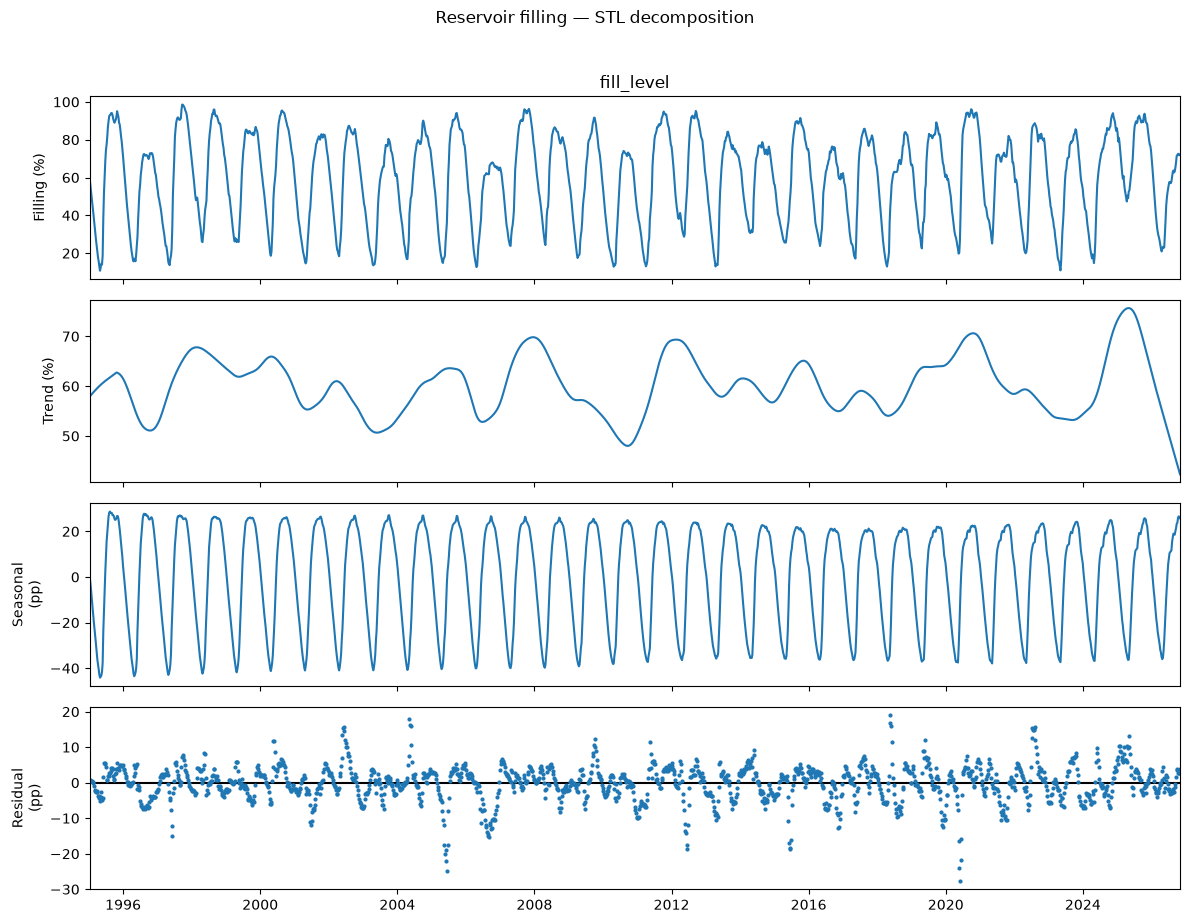

In [22]:
fig_stl = plot_reservoir_stl(
    reservoir_no3,
    seasonal_smoother=13,
    trend_smoother=83,
    robust=True
)

display(fig_stl)
plt.close(fig_stl)

#### Graph comment
The top graph shows the reservoir filling level rises and falls in a clear yearly cycle. Since the flacutations happends around the same time each year. Aslo the trend i n the second top graph shows the trend and the third shos the seasonal pattern. The last graph is a residual graph where most residuals are close to zero. This means the trend and seasonal pattern together explain most of the observed changes. The reservior was 20-30 percent a few weeks.

In [23]:
from scipy.signal import spectrogram
import matplotlib.dates as mdates

def plot_reservoir_spectrogram(
    reservoir_df, window_length=156, window_overlap=104
):
    """Plot a spectrogram of weekly reservoir filling levels."""
    series = (
        reservoir_df.sort_values("date")
        .set_index("date")["fill_level"]
        .asfreq("W-SUN")
    )

    if not np.isfinite(series.to_numpy()).all():
        raise ValueError("The weekly series must have no missing or infinite values.")

    if not 2 <= window_length <= len(series):
        raise ValueError("Window length must be between 2 and the series length.")

    if not 0 <= window_overlap < window_length:
        raise ValueError("Overlap must be non-negative and smaller than the window.")

    # One observation per week: frequencies are measured in cycles per week.
    frequencies, times, power = spectrogram(
        series.to_numpy(),
        fs=1.0,
        window="hann",
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    # Convert window-centre times from elapsed weeks to calendar dates.
    dates = series.index[0] + pd.to_timedelta(times * 7, unit="D")

    # Express power relative to the strongest value, in decibels.
    relative_power = power / max(power.max(), np.finfo(float).tiny)
    power_db = 10 * np.log10(np.maximum(relative_power, 1e-12))

    fig, ax = plt.subplots(figsize=(12, 5))
    mesh = ax.pcolormesh(
        mdates.date2num(dates.to_pydatetime()),
        frequencies * 52,
        power_db,
        shading="auto",
        cmap="viridis"
    )

    # Focus on slower cycles, including the annual cycle.
    ax.set_ylim(0, 6)
    ax.axhline(1, color="white", linestyle="--", label="52-week cycle")
    ax.set(
        title="Reservoir filling ÔÇö Spectrogram",
        xlabel="Date",
        ylabel="Cycles per 52 weeks"
    )
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()
    fig.colorbar(mesh, ax=ax, label="Power relative to maximum (dB)")
    fig.tight_layout()

    return fig

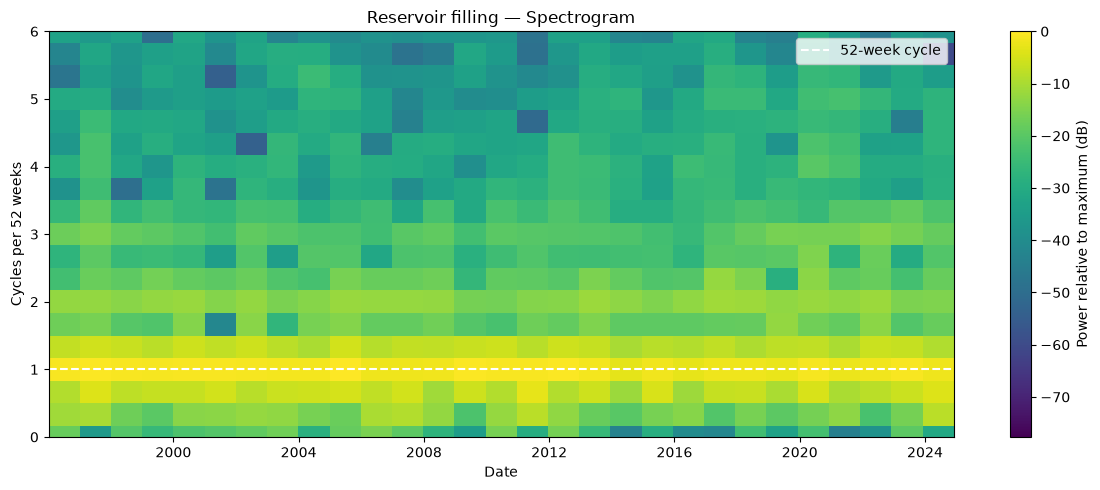

In [24]:
fig_spectrogram = plot_reservoir_spectrogram(
    reservoir_no3,
    window_length=156,
    window_overlap=104
)

display(fig_spectrogram)
plt.close(fig_spectrogram)

#### Graph comment

The spectogram shows from left to right when the pattern was present, here it seem to be from around 1980 to around 2024. From the bottom to top it showed how often the pattern repeats. 1 means every 52 weeks, and 2 means around every 26 weeks and so on. Strong yellow which is shown here means that it is a strong repeating pattern and light blue it is a weak pattern. In the spectogram above there is a white dashed line at 1 this shows that there is a strong yearly pattern within the year in the reservoir. 

### Work log

I started by loading NVEÔÇÖs shapefiles for the electricity and precipitation regions in Jupyter Notebook. Then combined the precipitation areas into East, North, and West, then sampled 1,000 locations inside each region. I also converted the coordinates to longitude and latitude for use with Open-Meteo.

Then I created the function to download hourly ERA5 temperature and precipitation for a selected region and date range. I struggled with setting up this function and needed more help from AI than I would have liked. Downloading data for all 1,000 NO3 locations for 2024 also took some time. Since the API rate limits interrupted the process, so I saved each completed location to allow the download to resume. Then i checked for missing values, duplicate records, and complete hourly coverage before calculating the regional averages.

For the precipitation part, i used DCT filtering and robust statistics to calculate SPC limits and highlight outliers. For temperature, I used Local Outlier Factor with a default outlier proportion of one percent. I also performed STL decomposition and created a spectrogram using weekly reservoir filling data. A strong yearly pattern was shown.

In Streamlit, i added two analysis pages, each with two tabs. Reservoir Analysis contains STL and the Spectrogram, while Weather Analysis contains SPC and LOF. I found it was easier to copy the functions from the notebook into a analysis_function file and etc so that it was easier to import the functions to the streamlit python file. The weather selection follows the shared reservoir area type and supports electricity and precipitation regions. The app uses saved NO3 averages for 2024 and two sampled locations for other downloads.

In general the assignment took longer than i expected, especially downloading the data and debugging functions. I fixed a missing dependency in Streamlit Cloud and removed unnecessary folders from the main branch on GitHub, including the raw weather cache and a Windows-generated folder. I tested the new pages locally and online. I would like to revisit the code afterwards so I can understand the functions more independently and rely less on AI assistance.

### AI usage

I used ChatGPT as support when working with Python, Streamlit, and GitHub. It helped me understand error messages, discuss possible solutions, and explain some concepts. AI also helped with generating the workflow. 

I received code suggestions and debugging help, particularly for the weather download function, handling API rate limits, and creating the Streamlit analysis pages. I also asked for guidance on connecting the area selectors to the weather data, updating dependencies, merging branches, removing generated files from Git tracking, and updating `.gitignore`.

I tested the code and inspected the data, plots, and app outputs throughout the process. I also used ChatGPT to help formulate graph comments, the work log. I relied on more assistance than I initially intended, especially when I encountered technical problems. 